# Task 1

## SGA Process (Pseudocode)

```
Initialize population P
Evaluate fitness of each individual in P
While termination condition not met:
    Select parents from P
    Apply crossover and mutation to create offspring
    Evaluate fitness of offspring
    Form new population P from offspring (and possibly elites)
Return best individual found
```

### Hyperparameters

1. **seed** Fixed number for the RNG to ensure reproducability.
2. **n_pop:** Controls the population size.
3. **n_bits:** Defines the number of bits in a single candidate solution.
4. **c_prob:** Probability that crossover (recombination) occurs between parent chromosomes.
5. **m_prob:** Determines how frequently random changes occur in the offspring.
6. **elitism:** Ensures that the best-performing individuals always survive into the next generation, preventing performance regression.
7. **n_iter:** Termination criteria. Fixed number of algorithm iterations or generations to produce. 

In [5]:
import random
import numpy as np
import matplotlib.pyplot as plt

hyperparameters = {
    "seed": 22040,
    "n_pop": 4,
    "n_bits": 6,
    "c_prob": 0.9,
    "m_prob": 0.01,
    "elitism": 0.05,
    "n_iter": 100,
}

seed = hyperparameters["seed"]
random.seed(seed)
np.random.seed(seed)


### Conversion functions

Integer values are encoded as 6-bit binary strings (represented as a list) e.g., [0, 0, 0, 0, 1, 1] is 3. Values encoded as integers range from 0 to 63.

**Phenotype:** Integer value (e.g., 17)

**Genotype:** 6-bit binary string (e.g., [0, 0, 1, 0, 1, 0]).

In [6]:
def geno_to_pheno(individuals):
    "Returns a list of the integer values corresponding to their the 6-bit binary value."
    return [int("".join(map(str, individual)), 2) for individual in individuals]

def pheno_to_geno(x_values):
    "Returns a 6-bit binary string encoded as a list of integers."
    return [[int(bit) for bit in format(x_value, '06b')] for x_value in x_values]

### Initialization Function: (Inputs: Population Size; Output: Individuals). 

This separate function `initialization_population` will create the individuals for the population, each having six binary genes. 

It should return the individuals, for example as a list of lists e.g., [[0, 1, 1, 0, 1,0], [0, 1, 1, 1, 1,1], [1, 0, 1, 0, 1,1]].

In [7]:
def initialization_population( pop_size: int, num_bits: int=6  ) -> list[list[int]]:
    "Initializes n_pop individuals as the working population."
    population = []
    for _ in range(pop_size):
        population.append(np.random.randint(0, 2, num_bits, int).tolist()) # individual (6-bit binary string)
    return population

### Initalization Subtask 

Use this function to generate 4 individuals and state those specific individuals generated (and the type of output e.g., a list of lists).

In [ ]:
def initialize_population_subtask():
    individuals_geno = initialization_population(4, 6)

    print("Individuals Generated (Genotype):")
    for num, individual in enumerate(individuals_geno):
        print(f"{num + 1}: {individual}")

initialize_population_subtask()

Individuals Generated (Genotype):
1: [0, 0, 1, 1, 0, 1]
2: [0, 0, 1, 0, 1, 1]
3: [1, 0, 1, 1, 1, 0]
4: [1, 1, 1, 0, 1, 0]


### Fitness Function: (Inputs: Individuals; Output: Fitness values). 

This separate function `fitness` takes as input one or multiple individuals (genotype), uses the geno to pheno function to convert them to the integer value
(phenotype) and calculates the fitness value for all of them (as specified above).

In [9]:
def fitness( individuals: list[list[int]] ) -> list[float]:
    "Returns the fitness values for a list of individuals."
    coeffs_exps_pairs = [
        (-0.00008333, 6),
        (-0.001, 5),
        (0.09375, 4),
        (1.16667, 3),
        (-19.53125, 2),
        (-234.375, 1),
        (8350, 0)
    ]

    def evaluate( value: float ) -> float:
        y_val = value - 64 if value >= 32 else value 
        return sum(
                coeff * y_val**exp
                for coeff, exp in coeffs_exps_pairs
        )

    return [evaluate(value) for value in geno_to_pheno(individuals)]

### Testing Fitness

**Subtask:** Check that for individual = [[0, 1, 0, 1, 0, 1]] the fitness value is approximately 12620.97. Also, plot the fitness landscape (x-axis: integer values (phenotype); y-axis: fitness) based on all possible integer values (phenotype). State also what x-values correspond to the minimum and to the maximum (fitness).

Individual (Geno)  | Expected Fitness | Actual Fitness 
-------------------|------------------|---------------
[0, 1, 0, 1, 0, 1] | 12_620.97        | 12_620.976507

Fitness score within range: [12_620,12_621]

Plotting distribution of fitness scores for all possible phenotype values (0 - 63):


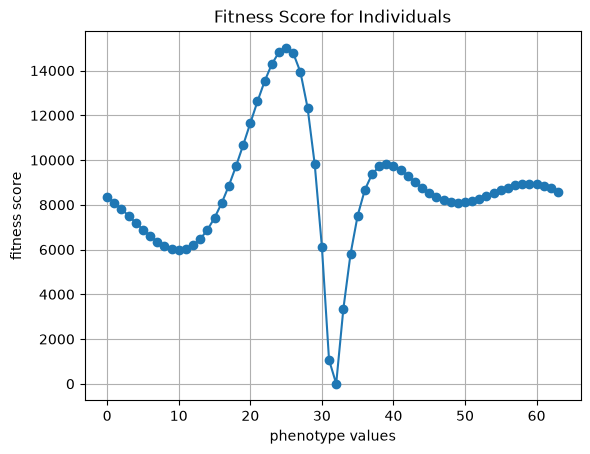

X values corresponding to minimum/maximum fitness:

X value (pheno) | Fitness Value
----------------|--------------
32              | 4.0832461
25              | 15024.0429688


In [109]:
def fitness_subtask( individual: list[list[int]], samples: int ):
    """Performs subtask"""
    expected = 12_620.97
    fitness_value = fitness(individual)

    print(f"Individual (Geno){"":<1} | Expected Fitness | Actual Fitness ")
    print("-" * 19 + "|" + "-" * 18 + "|" + "-" * 15)
    print(f"{individual[0]} | {expected:_} {"":<6} | {fitness_value[0]:_.6f}\n")

    if 12_620 <= fitness_value[0] <= 12_621:
        print(f"Fitness score within range: [{12_620:_},{12_621:_}]\n")
    else:
        print(f"Fitness score not within range: [{12_620:_},{12_621:_}]\n")

    print(f"Plotting distribution of fitness scores for all possible phenotype values (0 - 63):")
    x_vals = list(range(samples))
    fitness_values = fitness(pheno_to_geno(x_vals))

    x_min = np.argmin(fitness_values)
    x_max = np.argmax(fitness_values)

    plt.plot(x_vals, fitness_values, marker='o')
    plt.title("Fitness Score for Individuals")
    plt.xlabel("phenotype values")
    plt.ylabel("fitness score")
    plt.grid(True)
    plt.show()

    print("X values corresponding to minimum/maximum fitness:\n")
    print("X value (pheno) | Fitness Value")
    print("-" * 16 + "|" + "-" * 14)    
    print(f"{x_min:<15} | {fitness_values[x_min]:.7f}")
    print(f"{x_max:<15} | {fitness_values[x_max]:.7f}")

fitness_subtask([[0, 1, 0, 1, 0, 1]], 64)

In [ ]:

def generate_population_and_fitness_values( samples: int=64 ) -> tuple[list[int], list[float], float, float]:
    x_values = list(range(samples))
    fitness_values = fitness(x_values)
    x_min = np.argmin(fitness_values)
    x_max = np.argmax(fitness_values)
    return x_values, fitness_values, x_min, x_max


### Parent Selection Function: (Inputs: Individuals, Fitness values; Output: Parents (in random order, same number as individuals)). 

This separate function `parent_selection` should perform fitness-proportional parent selection (as discussed in class) so that more fit parents have a higher probability to be selected. One function that may be of help here is *numpy.random.choice* from the *numpy* module.

In [38]:
def parent_selection( individuals: list[list[int]], fitness_values: list[list[float]] ) -> list[list[int]]:
    "Returns a list of the selected parents proportional to the individuals fitness values."
    fitness = np.array(fitness_values, dtype=float)
    probs = fitness / fitness.sum()
    idx = np.random.choice(len(individuals), size=len(individuals), replace=True, p=probs)
    return [individuals[i] for i in idx]

### Testing Parent Selection

**Subtask:** You saw from the previous subtask the fitness landscape. Test the parent selection by providing as the set of four individuals: the one leading to minimum fitness, to maximum fitness and two more individuals of moderate fitness (middle of fitness range). State which specific 4 individuals are in the set you tested, their fitness values and the parents the function provided. Hint: The highest fitness individual should (usually) be selected more often than the minimum fitness one (select a suitable run to show this).

In [ ]:


def select_test_subjects() -> tuple[list[int], list[float]]:
    "Selects and returns test subjects (x values) based on their fitness level (min, medium, medium, max)."

    
    fitness_vals list[float], x_min: int, x_max: int

    mid_fit = (fitness_vals[x_min] + fitness_vals[x_max]) / 2
    closest = np.argsort(np.abs(np.array(fitness_vals) - mid_fit))
    x_mod1, x_mod2 = closest[0], closest[1]

    x_values = [x_min, x_mod1, x_mod2, x_max]
    fit_vals = [
        fitness_vals[x_min],
        fitness_vals[x_mod1],
        fitness_vals[x_mod2],
        fitness_vals[x_max]
    ]

    return x_values, fit_vals


def parent_selection_subtask( x_values: list[int], fit_vals: list[float],
                          num_iter: int=1,  require_max_most: bool=False ) -> list[list[int]]:
    "Performs N iterations on the parent selection process, printing the selection rate/count for each."

    x_vals_geno = pheno_to_geno(x_values)
    counts = { val : 0 for val in x_values }
    x_max = x_values[np.argmax(fit_vals)]
    n, attempts = num_iter, 0

    while n > 0:
        attempts += 1
        parents = parent_selection(x_vals_geno, fit_vals)
        run_counts = {val: 0 for val in x_values}
        for p in geno_to_pheno(parents):
            run_counts[p] += 1

        # For single-iteration we employ discriminatory parent selecting,
        # i.e. selecting the run where x_max is counted the most.
        if require_max_most and run_counts[x_max] < max(run_counts.values()):
            continue  # reject this run, nothing added to totals

        for val, c in run_counts.items():
            counts[val] += c
        n -= 1

    if require_max_most:
        print(f"Accepted run after {attempts} attempt(s)")

    for individual, fitness_val, x_val in zip(x_vals_geno, fit_vals, x_values):
        rate = counts[x_val] / (num_iter * len(x_values)) * 100
        last_field = (
            f"Selection Rate: {rate:.4f}%"
            if num_iter > 10
            else f"Selected: {counts[x_val]}x"
        )

        print(
            f"Individual: {str(individual)}, {str(x_val):<5} "
            f"Fitness: {fitness_val:<12.4f} "
            f"{last_field}"
        )

    return parents




x_values, fit_vals = select_test_subjects()

# Single iteration parent_selection run for the x values
print("Single parent selection run: ")

parents = parent_selection_test(x_values, fit_vals, require_max_most=True)
print(f"Parents Selected: {parents}\n")

# Multiple iteration parent_selection runs for x values, highlighting selection rate
num_iter = 10_000
print(f"\nMultiple parent selection run ({num_iter} iterations):" )
parents = parent_selection_test(x_values, fit_vals, num_iter)

Single parent selection run: 
Parents Selected: [[0, 1, 1, 0, 0, 1], [0, 1, 1, 0, 0, 1], [0, 0, 0, 0, 1, 1], [0, 0, 0, 0, 1, 1]]


Multiple parent selection run (10000 iterations):


[[0, 1, 1, 0, 0, 1],
 [0, 1, 1, 0, 0, 1],
 [0, 0, 0, 0, 1, 1],
 [0, 0, 0, 0, 1, 1]]

### Recombination (Crossover) Function: (Inputs: Parents, Crossover Probability $P_C$; Outputs: Offspring (pre-Mutation)). 

This separate function `one_point_crossover` performs 1-point crossover and generates for parents 1 & 2, parents 3 & 4 etc. offspring (and e.g., provides all offspring as a list of lists). Keep in mind that you can use a random uniform number $\in [0, 1]$ and compare it against the crossover probability, if it does not exceed it, crossover is performed (with a random cutoff point, using *randint* function in *random* module), otherwise, the two parents are simply copied to be the offspring.

In [ ]:
def one_point_crossover( parents: list[list[int]], crossover_prob: float ) -> list[list[int]]:
    offsprings = []
    for i in range(0, len(parents)-1, 2):
        parent1, parent2 = parents[i], parents[i+1]
        offspring1, offspring2 = parent1.copy(), parent2.copy()

        alpha = np.random.uniform(0, 1)
        if alpha <= crossover_prob:
            cpoint = random.randint(1, len(parent1) - 1)
            offspring1 = parent1[:cpoint] + parent2[cpoint:]
            offspring2 = parent2[:cpoint] + parent1[cpoint:]

        offsprings.append(offspring1)
        offsprings.append(offspring2)

    return offsprings

### Testing Recombination (Crossover)

**Subtask:** Use two parents as input and try out the function. State (as genotypes) the two parents, the offspring, and where the random cutoff point apparently was (you can deduce it by comparing the parents with the child, if you select suitable parents).

In [48]:
def find_cutoff(parent1, offspring1):
    for i, (p, o) in enumerate(zip(parent1, offspring1)):
        if p != o:
            return i
    return None  # identical: no crossover happened


parent1, parent2 = [0, 1, 1, 1, 0, 0], [1, 0, 0, 0, 1, 1] # 28 and 35
parents = [parent1, parent2]
offsprings = one_point_crossover( parents, 0.85 )
offspring1, offspring2 = offsprings[0], offsprings[1]

parent_items = [str(parent) for parent in parents]
offspring_items = [str(offspring) for offspring in offsprings]

label_width = 12
column_width = max(map(len, parent_items + offspring_items)) + 2

print(f"{'Cutoff Point:':<{label_width + 2}}" + f"{find_cutoff(parent1, offspring1)}\n")

print(f"{'Parents:':<{label_width}}" +
      "".join(f"{item:<{column_width}}" for item in parent_items))

print(f"{'Offsprings:':<{label_width}}" +
      "".join(f"{item:<{column_width}}" for item in offspring_items))


Cutoff Point: 4

Parents:    [0, 1, 1, 1, 0, 0]  [1, 0, 0, 0, 1, 1]  
Offsprings: [0, 1, 1, 1, 1, 1]  [1, 0, 0, 0, 0, 0]  


### Mutation Function: (Inputs: Individuals, Mutation Probability $P_M$; Outputs: Offspring (mutated)). 

This separate function `mutation` performs bitflip mutation for each bit / gene and each individual with mutation probability $P_M$. Similarly to crossover, keep in mind that you can use a random uniform number $\in [0, 1]$ and compare it against the mutation probability, if it does not exceed it, the value for the gene is flipped (e.g., from 0 to 1 or vice versa).

In [61]:
def mutation( individuals: list[list[int]], mutation_prob: float ) -> list[list[int]]:
    mutated = []
    for individual in individuals:
        offspring = individual.copy()
        
        if np.random.uniform(0, 1) <= mutation_prob:
            for i in range(0, len(individuals)-1):
                offspring[i] = 1 - individuals[i] # flipping each bit
            mutated.append(offspring)
    return mutated

### Testing Mutation Function

**Subtask:** Use one individual as input and perform mutation for that individual - once with probability of 0.2 and once with a probability of 0.9. State (as a genotype) the original individual and the two (mutated) individuals. Comment on whether the number of mutations that occurred corresponds to your expectation and why.

In [70]:
individual = [0, 1, 0, 1, 1, 0] # 22
mut_prob1, mut_prob2 = 0.2, 0.9

label_width = 27

mutated1 = mutation( [individual], mut_prob1 )
mutated2 = mutation( [individual], mut_prob2 )

print(f"{'Individual Pre-Mutation:':<{label_width}}" + f"{individual}")
print(f"{'Post-Mutation (prob. 0.2):':<{label_width}}" + f"{mutated1}")
print(f"{'Post-Mutation (prob. 0.9):':<{label_width}}" + f"{mutated2}")

Individual Pre-Mutation:   [0, 1, 0, 1, 1, 0]
Post-Mutation (prob. 0.2): []
Post-Mutation (prob. 0.9): [[0, 1, 0, 1, 1, 0]]


### Survivor Selection Function: (Inputs: Individuals, Offspring, Fitness Individuals, Fitness Offspring; Outputs: (New) population). 

This separate function `survivor_selection` performs deterministic survivor selection (no randomness / stochasticity here) by taking from among the population individuals and the offspring the survivors based on the highest fitness values (population size should remain the same!).

In [ ]:
def survivor_selection( individuals: list[list[int]], offspring: list[list[int]],
                        fitness_individuals: list[float], fitness_offspring: list[float]) -> list[list[int]]:
    pass

NameError: name 'offspring' is not defined

### Testing Survivor Selcction Function

**Subtask:** Provide to the function one current population individual and one offspring, together with their respective fitness values. State both individuals (genotypes), their fitness values, and the one survivor returned, ensuring that the fitter individual was selected to survive.

### **Loop:** 

Now create the complete version of the simple genetic algorithm (SGA), using the functions previously coded. Specifically, initialize the population and then loop (for a number of iterations to be specified) over those steps that should be repeated in the SGA.

**Subtask:** Make sure to display the average and best fitness in each iteration. Is the average and best fitness non-decreasing? Why / why not? Is this according to your expectation (knowing the specifics of the SGA implementation). Why / why not?